<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day03_Score_Matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

On Day 3 we'll built students, projects, ranked preferences and skill fit. Today we'll combine them into a single table with one happiness score per student-project pair.

Two ideas for today

Idea 1: the score table. Optimisation methods can't work with "rank 2 plus a good skill fit". They need one number for each pair, where a higher number means a better match. We build it from two parts: how much the student wants the project (their rank) and how well their skills fit it.

Idea 2: weights are choices about values. How much should preference count compared with skills? If we say "preference matters most", the program serves what students want. If we say "skills matter most", it serves what projects need. Neither is correct. It's a decision someone has to make, and today you'll see how much it changes the picture.

In [1]:
import os, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("students.csv"):
    subprocess.run(["git", "clone", "-q", "https://github.com/buntyedutainer/allocation-optimizer", "repo"])
    subprocess.run("cp repo/data/*.csv .", shell=True)

print([f for f in ["students.csv", "projects.csv", "preferences.csv"] if os.path.exists(f)])

['students.csv', 'projects.csv', 'preferences.csv']


Load the data.

In [2]:
students = pd.read_csv("students.csv", index_col=0)
projects = pd.read_csv("projects.csv", index_col=0)
projects["needs"] = projects["needs"].str.split(";")
prefs = pd.read_csv("preferences.csv")

print(len(students), "students,", len(projects), "projects,", projects["capacity"].sum(), "places")

40 students, 10 projects, 44 places


Skill fit again. This is the same calculation as Day 2: the student's average level on the skills a project needs, divided by 3.

In [3]:
def fit_matrix(students, projects):
    fit = pd.DataFrame(index=students.index, columns=projects.index, dtype=float)
    for pid, row in projects.iterrows():
        fit[pid] = students[row["needs"]].mean(axis=1) / 3
    return fit

fit = fit_matrix(students, projects)
fit.round(2).head(3)

project_id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10
S01,0.50,0.50,0.50,0.50,0.5,0.33,0.50,0.67,0.50,0.56
S02,0.33,0.17,0.50,0.33,0.5,0.00,0.67,0.67,0.33,0.56
S03,0.67,1.00,0.33,0.67,0.5,0.83,0.17,0.50,0.67,0.44


Turn ranks into points. Rank 1 is worth 10 points, rank 2 is worth 8, and so on. A project the student didn't list gets 0.

In [4]:
RANK_POINTS = {1: 10, 2: 8, 3: 6, 4: 4, 5: 2}

pref_points = pd.DataFrame(0.0, index=students.index, columns=projects.index)
for _, row in prefs.iterrows():
    pref_points.loc[row["student_id"], row["project_id"]] = RANK_POINTS[row["rank"]]

pref_points.head(3)

project_id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10
S01,10.0,2.0,8.0,0.0,0.0,6.0,0.0,0.0,4.0,0.0
S02,10.0,0.0,8.0,0.0,0.0,2.0,0.0,6.0,4.0,0.0
S03,10.0,8.0,6.0,0.0,0.0,4.0,0.0,2.0,0.0,0.0


Combine them into one score. Preference counts for 70% and skill fit for 30%. Both parts run from 0 to 10, so the final score does too.

In [6]:
W_PREF, W_FIT = 0.7, 0.3

score = W_PREF * pref_points + W_FIT * (10 * fit)
score = score.round(2)

print("Lowest score:", score.values.min(), "| highest:", score.values.max())
score.head(3)

Lowest score: 0.0 | highest: 10.0


project_id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10
S01,8.5,2.9,7.1,1.5,1.5,5.2,1.5,2.0,4.3,1.67
S02,8.0,0.5,7.1,1.0,1.5,1.4,2.0,6.2,3.8,1.67
S03,9.0,8.6,5.2,2.0,1.5,5.3,0.5,2.9,2.0,1.33


Look at the whole table.

Each row is a student. Bright cells are good matches, and you should see which projects are bright for many students at once.

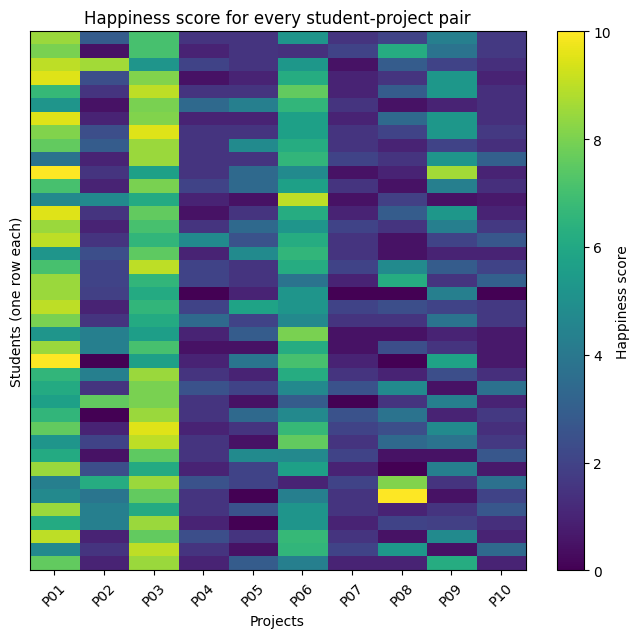

In [7]:
plt.figure(figsize=(8, 7))
plt.imshow(score.values, aspect="auto", cmap="viridis")
plt.colorbar(label="Happiness score")
plt.xticks(range(len(score.columns)), score.columns, rotation=45)
plt.yticks([])
plt.xlabel("Projects")
plt.ylabel("Students (one row each)")
plt.title("Happiness score for every student-project pair")
plt.show()

Does the score do something strange? An unlisted project can still earn up to 3 points from skill fit alone. A listed fifth choice with a poor fit scores lower than that. Let's count how often it happens.

In [8]:
listed = pref_points > 0
rows = []
for sid in score.index:
    worst_listed = score.loc[sid][listed.loc[sid]].min()          # lowest score among the 5 listed projects
    unlisted_scores = score.loc[sid][~listed.loc[sid]]
    better = (unlisted_scores > worst_listed).sum()               # unlisted projects that outscore it
    rows.append(better)

odd = pd.Series(rows, index=score.index)
print("Students with at least one unlisted project scoring above one of their listed projects:", int((odd > 0).sum()), "of", len(odd))
print("Total such pairs:", int(odd.sum()))

Students with at least one unlisted project scoring above one of their listed projects: 2 of 40
Total such pairs: 4


What do the weights change? For each student, find the project with the highest score. Then check how often it's also their first choice, for different weights.

In [9]:
first_choice = prefs[prefs["rank"] == 1].set_index("student_id")["project_id"]

print("Weight on preference | share of students whose top-scoring project is their first choice")
for w in [1.0, 0.7, 0.5, 0.3, 0.0]:
    sc = w * pref_points + (1 - w) * 10 * fit
    top = sc.idxmax(axis=1)
    agree = (top == first_choice.reindex(top.index)).mean()
    print(f"        {w:.1f}          |   {agree:.0%}")

Weight on preference | share of students whose top-scoring project is their first choice
        1.0          |   100%
        0.7          |   100%
        0.5          |   92%
        0.3          |   72%
        0.0          |   20%


How crowded is the top? If every student got their top-scoring project, how many would want each one, compared with its places?

In [10]:
top = score.idxmax(axis=1)
crowd = pd.DataFrame({"title": projects["title"], "places": projects["capacity"],
                      "students whose top score it is": top.value_counts()}).fillna(0)
crowd["students whose top score it is"] = crowd["students whose top score it is"].astype(int)
crowd["over capacity by"] = (crowd["students whose top score it is"] - crowd["places"]).clip(lower=0)
print(crowd)
print("\nStudents who would miss out if everyone got their top-scoring project:", int(crowd["over capacity by"].sum()))

                     title  places  students whose top score it is  \
P01         Data Dashboard       4                              18   
P02             Web Portal       4                               0   
P03         Chatbot Helper       3                              19   
P04       Learning Content       5                               0   
P05        Survey Analysis       5                               0   
P06             Mobile App       3                               2   
P07     Community Outreach       6                               0   
P08            UX Research       5                               1   
P09     Automation Scripts       5                               0   
P10  Social Media Campaign       4                               0   

     over capacity by  
P01                14  
P02                 0  
P03                16  
P04                 0  
P05                 0  
P06                 0  
P07                 0  
P08                 0  
P09          

Save the table and your settings.

In [11]:
score.to_csv("scores.csv")
fit.round(4).to_csv("fit.csv")
with open("config.json", "w") as f:
    json.dump({"rank_points": RANK_POINTS, "w_pref": W_PREF, "w_fit": W_FIT}, f, indent=2)
print("Saved scores.csv, fit.csv and config.json")

Saved scores.csv, fit.csv and config.json
